In [ ]:
# Instalando e exportando bibliotecas
!pip install psrqpy
from psrqpy import QueryATNF
import pandas as pd

# Baixando os dados (selecionei apenas 5 colunas do dataset original)
# não estou usando BINARY e DIST

query = QueryATNF(
    params=['TYPE', 'BINARY', 'P0', 'DM', 'DIST', 'ASSOC', 'AGE'],
    include_errs=False,
    condition=None,
    cache=True,
    version='latest'
)

df = query.pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 1.5 MB/s eta 0:00:00


In [ ]:
# Tamanho do dataset
len(df)

4351

In [ ]:
df.head()

,AGE,ASSOC,BINARY,DIST,P0,DM,TYPE
0,3.063207e+05,GRS,NaN,6.357,0.115364,218.6,HE
1,5.241664e+06,NaN,NaN,0.860,0.693748,11.4,NaN
2,1.388691e+04,GRS,NaN,1.400,0.315873,NaN,NRAD
3,NaN,NaN,NaN,5.399,2.552870,24.9,NaN
4,3.740843e+08,NaN,NaN,5.427,3.025301,131.3,RRAT


In [ ]:
# Valores que a coluna TYPE pode assumir
df['TYPE'].unique()

array(['HE', nan, 'NRAD', 'RRAT', 'AXP', 'XINS', ''], dtype=object)

In [ ]:
# Quantos de cada tipo de pulsar
df['TYPE'].value_counts()

,count
TYPE,
HE,253
RRAT,220
NRAD,93
AXP,24
XINS,8
,5


In [ ]:
# Porcentagem de cada tipo
df['TYPE'].value_counts(normalize=True) * 100

,proportion
TYPE,
HE,41.956882
RRAT,36.484245
NRAD,15.422886
AXP,3.980100
XINS,1.326700
,0.829187


In [ ]:
# Valores unicos de BINARY
df['BINARY'].unique()

array([nan, 'ELL1', 'DD', 'BTX', 'BT', 'T2', 'DDH', 'DDGR', 'DDS',
       'ELL1H', '?', 'BT2P', 'MSS', 'DDFWHE', 'ELL1H+', 'DDK'],
      dtype=object)

In [ ]:
# Estatistica descritiva
df[['P0', 'DM', 'DIST']].describe().T

,count,mean,std,min,25%,50%,75%,max
P0,4286.0,0.857041,1.885271,0.001396,0.142221,0.486014,1.022,75.885547
DM,4233.0,212.866378,207.697086,1.990000,59.816000,147.500000,297.000,1778.000000
DIST,4277.0,6.376653,7.197049,0.092000,2.520000,4.662000,7.566,100.000000


In [ ]:
# Valores únicos na coluna ASSOC
df['ASSOC'].unique()

array(['GRS', nan, 'GC', 'EXGAL', 'XRS', 'OPT', 'SNR', 'PWN', 'OC'],
      dtype=object)

In [ ]:
# Quantos pulsares tem cada associação
df['ASSOC'].value_counts(dropna=False)

# Neste caso, as familias não imporyam, oq importa é saber se o pulsar faz parte de uma associação ou não.

,count
ASSOC,
NaN,3668
GRS,303
GC,239
XRS,52
EXGAL,46
SNR,28
OPT,13
PWN,1
OC,1


In [ ]:
# Criando uma coluna para armazenar a variavel qualitativa binária TEM_ASSOC
df['TEM_ASSOC'] = df['ASSOC'].apply(lambda x: 'S' if pd.notna(x) else 'N')

In [ ]:
df.head()

,AGE,ASSOC,BINARY,DIST,P0,DM,TYPE,TEM_ASSOC
0,3.063207e+05,GRS,NaN,6.357,0.115364,218.6,HE,S
1,5.241664e+06,NaN,NaN,0.860,0.693748,11.4,NaN,N
2,1.388691e+04,GRS,NaN,1.400,0.315873,NaN,NRAD,S
3,NaN,NaN,NaN,5.399,2.552870,24.9,NaN,N
4,3.740843e+08,NaN,NaN,5.427,3.025301,131.3,RRAT,N


In [ ]:
df['TEM_ASSOC'].value_counts()

# Apenas 683 pulsares tem associação conhecida

,count
TEM_ASSOC,
N,3668
S,683


In [ ]:
df['TEM_ASSOC'].value_counts(normalize=True) * 100

# Proporção percentual entre TEM_ASSOC 'S' e 'N'

,proportion
TEM_ASSOC,
N,84.302459
S,15.697541


#**TABELAS DE FREQUENCIA & MEDIDAS DE RESUMO**

In [ ]:
# Quantidade de NaN em cada coluna
df[['TYPE', 'TEM_ASSOC', 'P0', 'DM', 'DIST', 'AGE']].isna().sum()

,0
TYPE,3748
TEM_ASSOC,0
P0,65
DM,118
DIST,74
AGE,1551


In [ ]:
# Tabela de frequencia de TEM_ASSOC

tabela_freq_TEM_ASSOC = pd.DataFrame({
    'Frequência Absoluta': df['TEM_ASSOC'].value_counts(),
    'Frequência Relativa (%)': df['TEM_ASSOC'].value_counts(normalize=True) * 100
})

display(tabela_freq_TEM_ASSOC)

,Frequência Absoluta,Frequência Relativa (%)
TEM_ASSOC,,
N,3668,84.302459
S,683,15.697541


In [ ]:
# Tabela de frequencia de TYPE

tabela_freq_TYPE = pd.DataFrame({
    'Frequência Absoluta': df['TYPE'].value_counts(),
    'Frequência Relativa (%)': df['TYPE'].value_counts(normalize=True) * 100
})

display(tabela_freq_TYPE)

,Frequência Absoluta,Frequência Relativa (%)
TYPE,,
HE,253,41.956882
RRAT,220,36.484245
NRAD,93,15.422886
AXP,24,3.980100
XINS,8,1.326700
,5,0.829187


In [ ]:
# Tabela de frequencia TYPE com dropna False para incluir Nan (pulsares não catalogados ainda)

tabela_freq_TYPE = pd.DataFrame({
    'Frequência Absoluta': df['TYPE'].value_counts(dropna=False),
    'Frequência Relativa (%)': df['TYPE'].value_counts(normalize=True, dropna=False) * 100
})

display(tabela_freq_TYPE)

,Frequência Absoluta,Frequência Relativa (%)
TYPE,,
NaN,3748,86.141117
HE,253,5.814755
RRAT,220,5.056309
NRAD,93,2.137440
AXP,24,0.551597
XINS,8,0.183866
,5,0.114916


In [ ]:
tabela_freq_TEM_ASSOC = pd.DataFrame({
    'Frequência Absoluta': df['TEM_ASSOC'].value_counts(dropna=False),
    'Frequência Relativa (%)': df['TEM_ASSOC'].value_counts(normalize=True, dropna=False) * 100
})

display(tabela_freq_TEM_ASSOC)

,Frequência Absoluta,Frequência Relativa (%)
TEM_ASSOC,,
N,3668,84.302459
S,683,15.697541


In [ ]:
df['ASSOC'].value_counts()

,count
ASSOC,
GRS,303
GC,239
XRS,52
EXGAL,46
SNR,28
OPT,13
PWN,1
OC,1


In [ ]:
# Medidas de resumo P0
df['P0'].describe()

,P0
count,4286.000000
mean,0.857041
std,1.885271
min,0.001396
25%,0.142221
50%,0.486014
75%,1.022000
max,75.885547


In [ ]:
# Medidas de resumo
medidas = df[['P0', 'DM', 'DIST']].describe().T

# variância e coeficiente de variação
medidas['variância'] = df[['P0', 'DM', 'DIST']].var()
medidas['CV (%)'] = (medidas['std'] / medidas['mean']) * 100

# formatando
display(medidas.round(4))

,count,mean,std,min,25%,50%,75%,max,variância,CV (%)
P0,4286.0,0.8570,1.8853,0.0014,0.1422,0.486,1.022,75.8855,3.5542,219.9743
DM,4233.0,212.8664,207.6971,1.9900,59.8160,147.500,297.000,1778.0000,43138.0795,97.5716
DIST,4277.0,6.3767,7.1970,0.0920,2.5200,4.662,7.566,100.0000,51.7975,112.8656


In [ ]:
# Medidas de resumo P0 e DM
medidas = df[['P0', 'DM']].describe().T

# variância e coeficiente de variação
medidas['variância'] = df[['P0', 'DM']].var()
medidas['CV (%)'] = (medidas['std'] / medidas['mean']) * 100

# formatando
display(medidas.round(4))

,count,mean,std,min,25%,50%,75%,max,variância,CV (%)
P0,4286.0,0.8570,1.8853,0.0014,0.1422,0.486,1.022,75.8855,3.5542,219.9743
DM,4233.0,212.8664,207.6971,1.9900,59.8160,147.500,297.000,1778.0000,43138.0795,97.5716


In [ ]:
# Medidas de resumo AGE
medidas_age = df[['AGE']].describe().T
medidas_age['variância'] = df[['AGE']].var()
medidas_age['CV (%)'] = (medidas_age['std'] / medidas_age['mean']) * 100

display(medidas_age)

,count,mean,std,min,25%,50%,75%,max,variância,CV (%)
AGE,2800.0,2.067421e+09,3.246396e+10,218.062529,1.685687e+06,1.036371e+07,1.210561e+08,1.635150e+12,1.053909e+21,1570.263644


#**VIZUALIZÇÕES COM MATPLOT E SEABORN**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import seaborn as sns

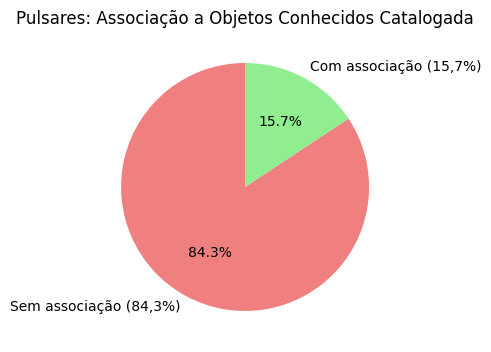

In [ ]:
plt.figure(figsize=(4, 8))
plt.pie(df['TEM_ASSOC'].value_counts(),
        labels=['Sem associação (84,3%)', 'Com associação (15,7%)'],
        autopct='%1.1f%%',
        colors=['lightcoral', 'lightgreen'],
        startangle=90)
plt.title('Pulsares: Associação a Objetos Conhecidos Catalogada')
plt.show()

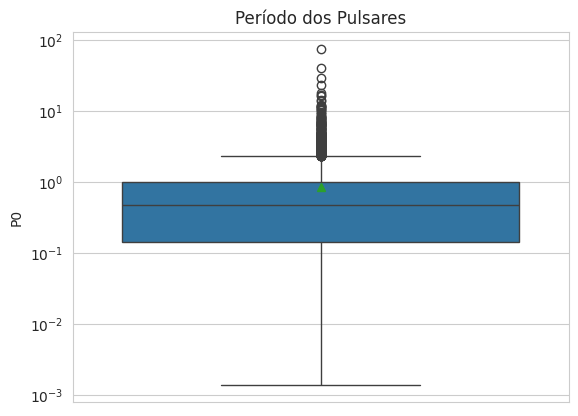

In [ ]:
# Boxplot do periodo P0

sns.boxplot(data=df, y='P0', showmeans=True)
plt.yscale('log')
plt.title('Período dos Pulsares')
plt.show()

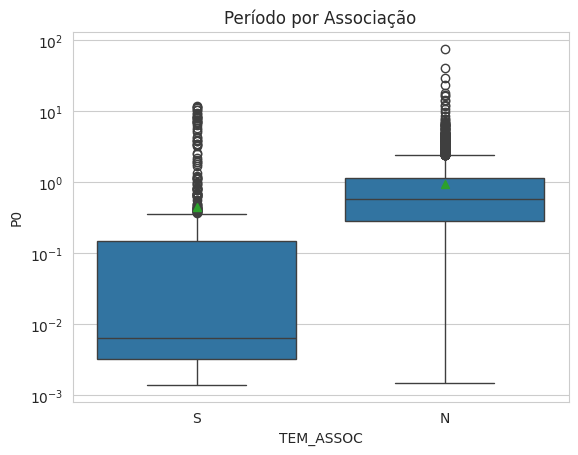

In [ ]:
# Boxplot comparando P0(Periodo de rotação) dos pulsares que tem associação e dos que não tem
sns.boxplot(data=df, x='TEM_ASSOC', y='P0', showmeans=True)
plt.yscale('log')
plt.title('Período por Associação')
plt.show()

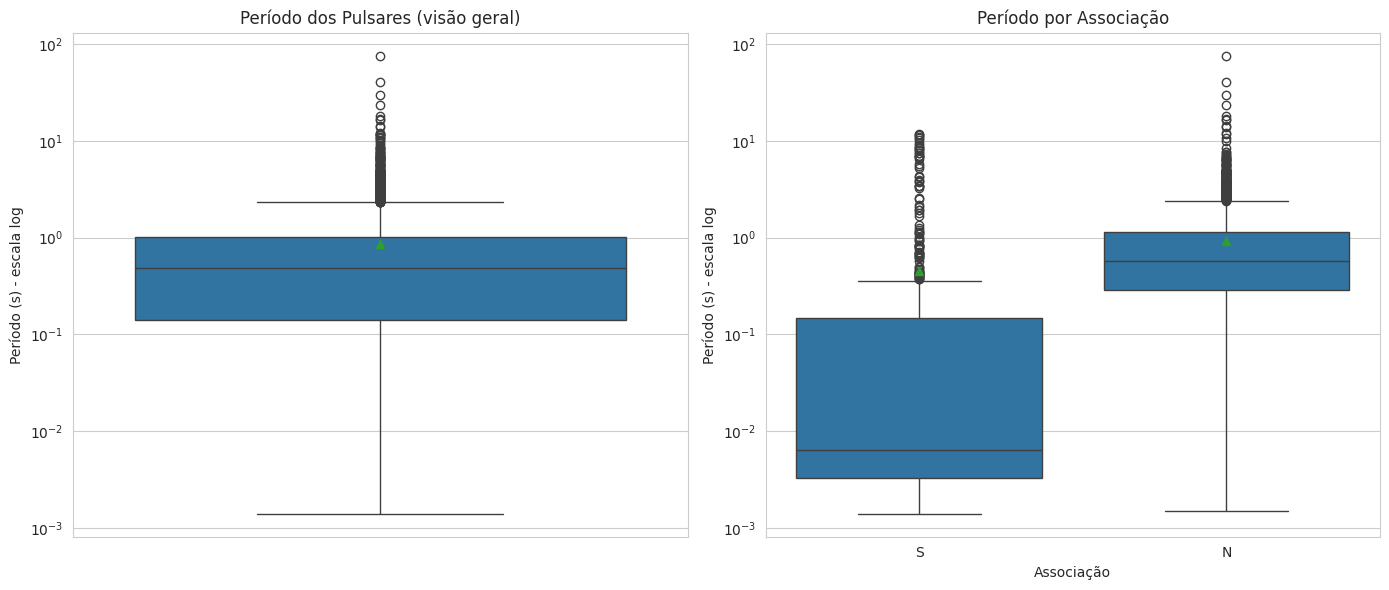

In [ ]:
# criando uma figura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# gráfico 1: Box plot todos (esquerda)
sns.boxplot(data=df, y='P0', showmeans=True, ax=ax1)
ax1.set_yscale('log')
ax1.set_title('Período dos Pulsares (visão geral)')
ax1.set_ylabel('Período (s) - escala log')
ax1.set_xlabel('')

# gráfico 2: Box plot por associação (direita)
sns.boxplot(data=df, x='TEM_ASSOC', y='P0', showmeans=True, ax=ax2)
ax2.set_yscale('log')
ax2.set_title('Período por Associação')
ax2.set_ylabel('Período (s) - escala log')
ax2.set_xlabel('Associação')

# layout para não sobrepor
plt.tight_layout()
plt.show()

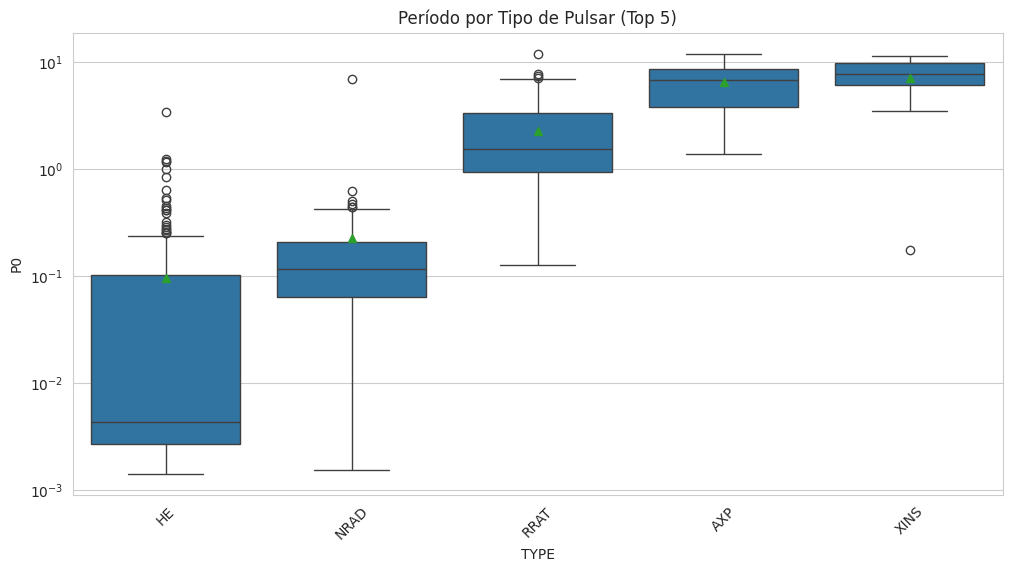

In [ ]:
# Box plot comparativo (TYPE vs P0)
plt.figure(figsize=(12, 6))

top_types = df['TYPE'].value_counts().head(5).index
df_top = df[df['TYPE'].isin(top_types)]

sns.boxplot(data=df_top, x='TYPE', y='P0', showmeans=True)

plt.yscale('log')
plt.title('Período por Tipo de Pulsar')
plt.xticks(rotation=45)
plt.show()

## Estudo - Correlação entre variaveis

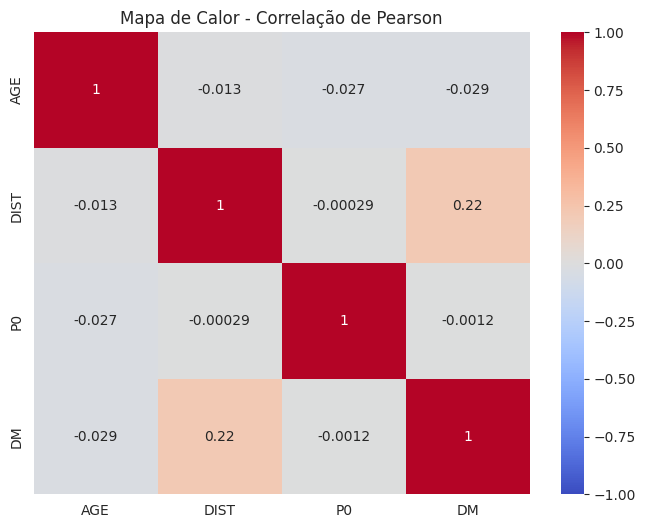

In [ ]:
# Matriz de correlação de Pearson

matriz_corr = df.corr(method='pearson', numeric_only=True)

plt.figure(figsize=(8,6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de Calor - Correlação de Pearson')
plt.show()

In [ ]:
df['AGE'].head(10)

,AGE
0,3.063207e+05
1,5.241664e+06
2,1.388691e+04
3,NaN
4,3.740843e+08
5,3.482575e+07
6,3.529201e+07
7,4.230558e+09
8,NaN
9,NaN


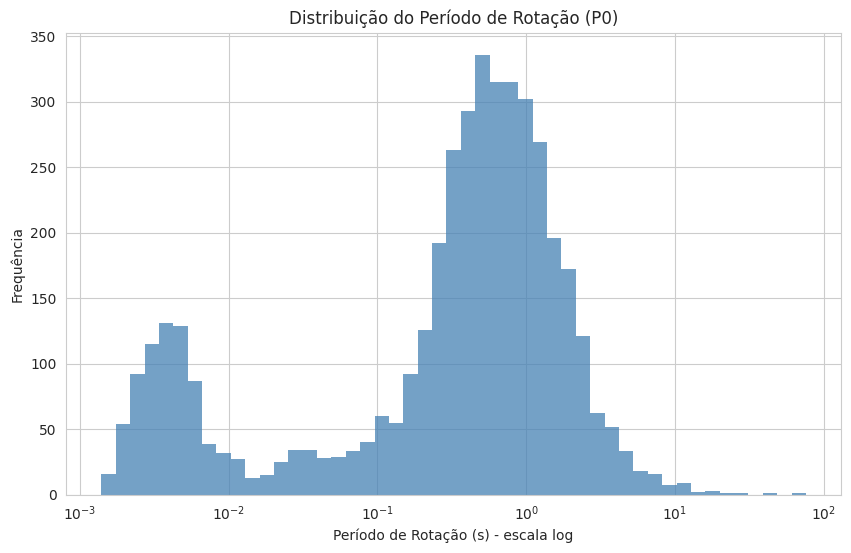

In [ ]:
# Histograma de P0 com bins em log
p0_clean = df['P0'].dropna()
bins_p0 = np.logspace(np.log10(p0_clean.min()), np.log10(p0_clean.max()), 50)

plt.figure(figsize=(10, 6))
sns.histplot(x=p0_clean, bins=bins_p0, kde=False, color='steelblue', edgecolor='black')
plt.xscale('log')
plt.xlabel('Período de Rotação (s) - escala log')
plt.ylabel('Frequência')
plt.title('Distribuição do Período de Rotação (P0)')
plt.show()

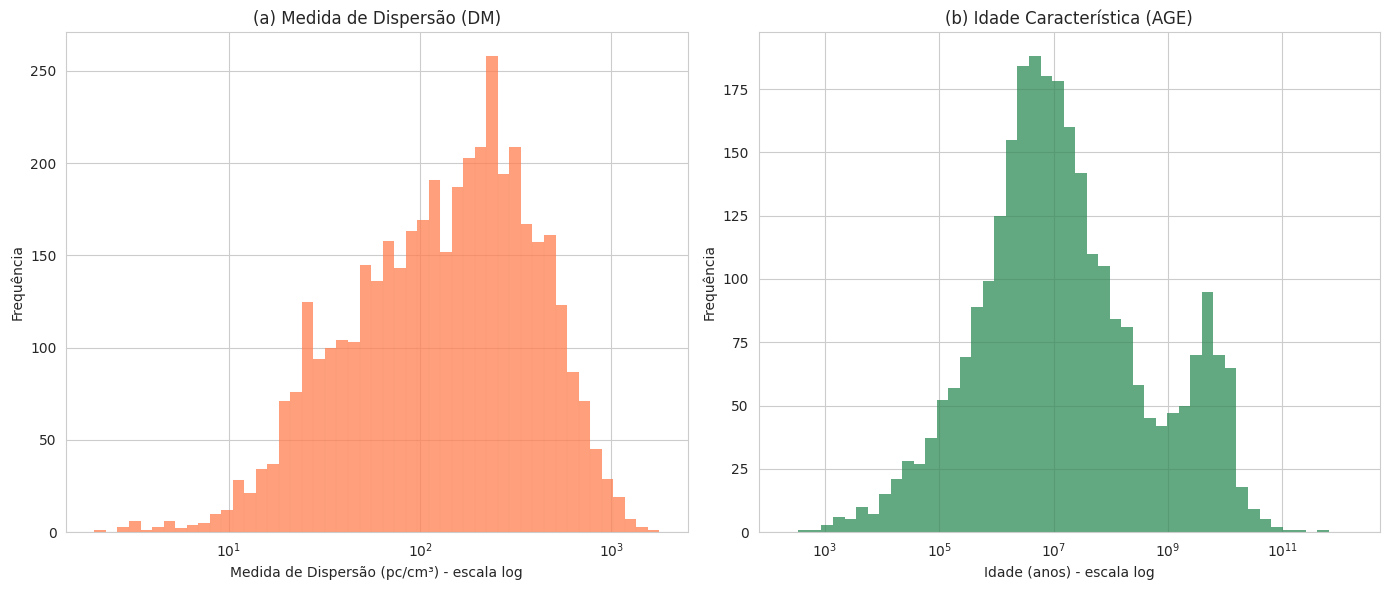

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# DM
dm_clean = df['DM'].dropna()
bins_dm = np.logspace(np.log10(dm_clean.min()), np.log10(dm_clean.max()), 50)

sns.histplot(x=dm_clean, bins=bins_dm, kde=False, color='coral', edgecolor='black', ax=ax1)
ax1.set_xscale('log')
ax1.set_xlabel('Medida de Dispersão (pc/cm³) - escala log')
ax1.set_ylabel('Frequência')
ax1.set_title('(a) Medida de Dispersão (DM)')
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'$10^{{{int(np.log10(x))}}}$'))

# AGE
age_clean = df['AGE'].dropna()
bins_age = np.logspace(np.log10(age_clean.min()), np.log10(age_clean.max()), 50)

sns.histplot(x=age_clean, bins=bins_age, kde=False, color='seagreen', edgecolor='black', ax=ax2)
ax2.set_xscale('log')
ax2.set_xlabel('Idade (anos) - escala log')
ax2.set_ylabel('Frequência')
ax2.set_title('(b) Idade Característica (AGE)')
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'$10^{{{int(np.log10(x))}}}$'))

plt.tight_layout()
plt.show()

In [ ]:
# dados validos para calcular correlação
validos = df[['P0', 'AGE']].dropna()
print(f"Pares válidos (P0 e AGE): {len(validos)} / {len(df)}")

# correlação apenas nos dados válidos
corr_valida = validos['P0'].corr(validos['AGE'])
print(f"Correlação P0 vs AGE (dados válidos): {corr_valida:.4f}")

Pares válidos (P0 e AGE): 2800 / 4351
Correlação P0 vs AGE (dados válidos): -0.0274


In [ ]:
print(df['AGE'].describe())

# valores de P0 e AGE juntos
print(df[['P0', 'AGE']].head(10))

# ver se há valores negativos ou zero em AGE
print(f"\nAGE negativa: {(df['AGE'] < 0).sum()}")
print(f"AGE zero: {(df['AGE'] == 0).sum()}")

count    2.800000e+03
mean     2.067421e+09
std      3.246396e+10
min      2.180625e+02
25%      1.685687e+06
50%      1.036371e+07
75%      1.210561e+08
max      1.635150e+12
Name: AGE, dtype: float64
         P0           AGE
0  0.115364  3.063207e+05
1  0.693748  5.241664e+06
2  0.315873  1.388691e+04
3  2.552870           NaN
4  3.025301  3.740843e+08
5  1.240699  3.482575e+07
6  2.314131  3.529201e+07
7  0.003050  4.230558e+09
8  0.005757           NaN
9  0.005358           NaN

AGE negativa: 0
AGE zero: 0


## Hipótese: Populações de Pulsares com comportamentos diferentes

## Separando as duas populações (Millisecond e Normais)

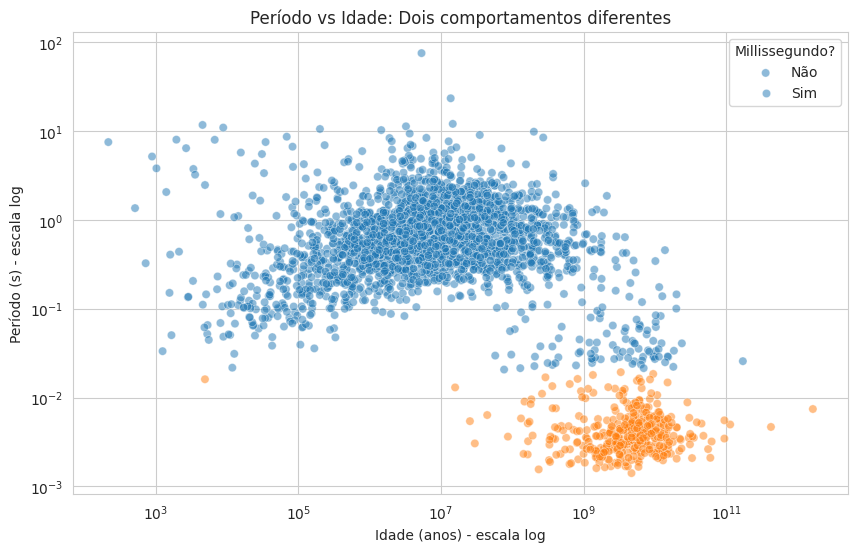

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='AGE', y='P0', alpha=0.5, hue=df['P0'] < 0.02)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Idade (anos) - escala log')
plt.ylabel('Período (s) - escala log')
plt.title('Período vs Idade: Dois comportamentos diferentes')
plt.legend(title='Millissegundo?', labels=['Não', 'Sim'])
plt.show()

In [ ]:
# Separar as duas populações
msp = df[df['P0'] < 0.02]      # Millisecond pulsars
normais = df[df['P0'] >= 0.02]   # Pulsares normais

print(f"Millissegundos: {len(msp)} pulsares")
print(f"Pulsares normais: {len(normais)} pulsares")

# Correlação apenas para pulsares normais
corr_normais = normais['P0'].corr(normais['AGE'])
print(f"Correlação P0 vs AGE (apenas normais): {corr_normais:.4f}")

# Correlação apenas para millissegundos
corr_msp = msp['P0'].corr(msp['AGE'])
print(f"Correlação P0 vs AGE (apenas MSP): {corr_msp:.4f}")

Millissegundos: 750 pulsares
Pulsares normais: 3536 pulsares
Correlação P0 vs AGE (apenas normais): -0.0364
Correlação P0 vs AGE (apenas MSP): 0.0344


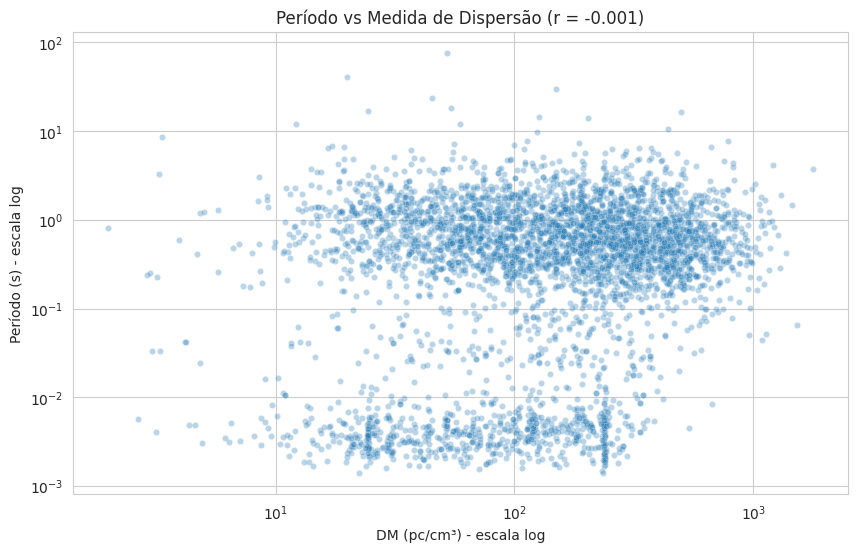

In [ ]:
plt.figure(figsize=(10, 6))

# Scatter plot
sns.scatterplot(data=df, x='DM', y='P0', alpha=0.3, s=20)

# Linha de regressão
#sns.regplot(data=df, x='DM', y='P0', scatter=False, color='red')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('DM (pc/cm³) - escala log')
plt.ylabel('Período (s) - escala log')
plt.title(f'Período vs Medida de Dispersão (r = {df["P0"].corr(df["DM"]):.3f})')
plt.show()

## P0 e DM, achei interessante a dispersão -->> vou dividir a população também

POPULACAO
Normal           3601
Millissegundo     750
Name: count, dtype: int64


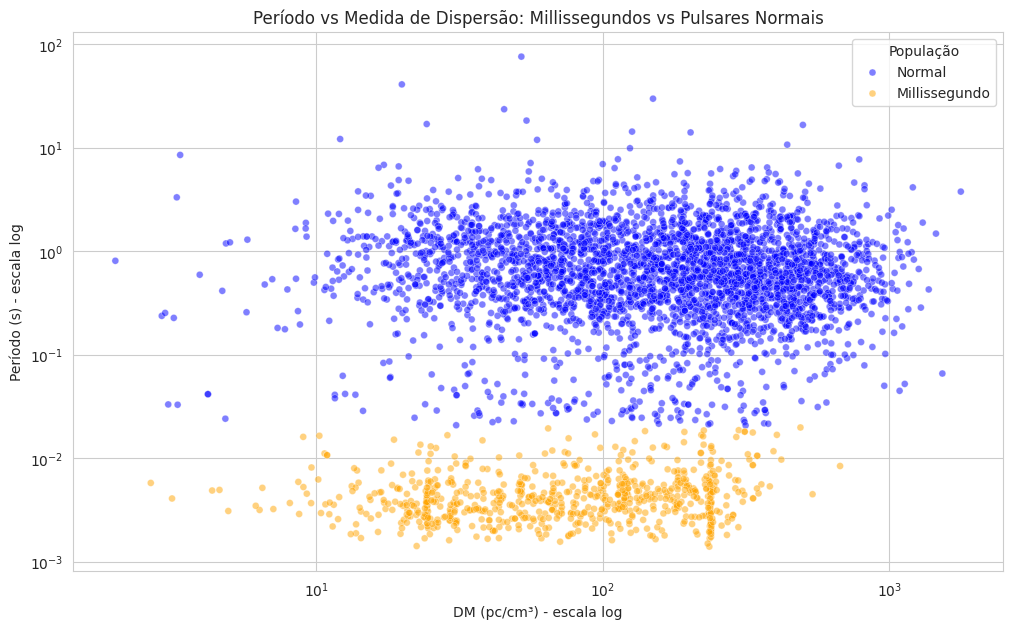

In [ ]:
# Criar uma coluna para classificar as populações
df['POPULACAO'] = df['P0'].apply(lambda x: 'Millissegundo' if x < 0.02 else 'Normal')

# Ver quantos tem em cada população
print(df['POPULACAO'].value_counts())

# Scatter plot com cores diferentes
plt.figure(figsize=(12, 7))

sns.scatterplot(data=df,
                x='DM',
                y='P0',
                hue='POPULACAO',
                alpha=0.5,
                s=25,
                palette={'Normal': 'blue', 'Millissegundo': 'orange'}
                )


plt.xscale('log')
plt.yscale('log')
plt.xlabel('DM (pc/cm³) - escala log')
plt.ylabel('Período (s) - escala log')
plt.title('Período vs Medida de Dispersão: Millissegundos vs Pulsares Normais')
plt.legend(title='População')
plt.show()

In [ ]:
# Versão do catalogo utilizada na analise
query.get_version

'2.7.0'